# PhytoVision: 4-model comparison
EfficientNetB0 (already trained) + 3 new models, all trained and scored the same way.
Run cells 1 to 5 in order. If Colab disconnects: reconnect (GPU on) and re-run cells 1 to 4. It resumes where it stopped.

In [2]:
# ===== CELL 1: setup (re-run after every disconnect) =====
!pip -q install kagglehub
import os, gc, time, numpy as np, pandas as pd, tensorflow as tf
import kagglehub
from google.colab import drive
from sklearn.metrics import precision_recall_fscore_support

print("GPU:", tf.config.list_physical_devices('GPU'))   # must NOT be empty

drive.mount('/content/drive')
OUT_DIR = '/content/drive/MyDrive/PhytoVision_4'
os.makedirs(OUT_DIR, exist_ok=True)
RESULTS_CSV = f'{OUT_DIR}/results.csv'
B0_PATH = '/content/drive/MyDrive/plant_disease_model_final.keras'   # your already-trained model
assert os.path.exists(B0_PATH), "EfficientNetB0 model not found in Drive root - fix B0_PATH"

# ---- knobs ----
NEW_MODELS = ['DenseNet121', 'MobileNetV3Large', 'ConvNeXtTiny']   # the 3 to train
IMG_SIZE = (224, 224)
BATCH = 32
P1_EPOCHS = 3     # phase 1: frozen backbone
P2_EPOCHS = 4     # phase 2: fine-tune last 30 layers

path = kagglehub.dataset_download("vipoooool/new-plant-diseases-dataset")
root = os.path.join(path, "New Plant Diseases Dataset(Augmented)", "New Plant Diseases Dataset(Augmented)")
train_dir, valid_dir = os.path.join(root, "train"), os.path.join(root, "valid")

train_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=IMG_SIZE, batch_size=BATCH, label_mode='categorical', shuffle=True, seed=42)
val_raw = tf.keras.utils.image_dataset_from_directory(
    valid_dir, image_size=IMG_SIZE, batch_size=BATCH, label_mode='categorical', shuffle=False)

class_names = train_raw.class_names
NUM_CLASSES = len(class_names)
y_true = np.array([class_names.index(os.path.basename(os.path.dirname(p))) for p in val_raw.file_paths])
print(NUM_CLASSES, "classes |", len(y_true), "val images")

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mounted at /content/drive
Using Colab cache for faster access to the 'new-plant-diseases-dataset' dataset.
Found 70295 files belonging to 38 classes.
Found 17572 files belonging to 38 classes.
38 classes | 17572 val images


In [3]:
# ===== CELL 2: helpers =====
A = tf.keras.applications
REGISTRY = {   # name: (constructor, module with its own preprocess_input)
    'EfficientNetB0':   (A.EfficientNetB0,   A.efficientnet),
    'DenseNet121':      (A.DenseNet121,      A.densenet),
    'MobileNetV3Large': (A.MobileNetV3Large, A.mobilenet_v3),
    'ConvNeXtTiny':     (A.ConvNeXtTiny,     A.convnext),
    # spare options if you want to swap one in: 'ResNet50V2', 'EfficientNetV2S', 'InceptionV3', 'Xception'
    'ResNet50V2':       (A.ResNet50V2,       A.resnet_v2),
    'EfficientNetV2S':  (A.EfficientNetV2S,  A.efficientnet_v2),
    'InceptionV3':      (A.InceptionV3,      A.inception_v3),
    'Xception':         (A.Xception,         A.xception),
}

def get_ds(name):
    pre = REGISTRY[name][1].preprocess_input        # each model needs its OWN preprocessing
    f = lambda x, y: (pre(x), y)
    tr = train_raw.map(f, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
    va = val_raw.map(f, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
    return tr, va

def compile_(m, lr):
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='categorical_crossentropy', metrics=['accuracy'])

def evaluate(name, model, va, train_min=np.nan):
    t = time.time()
    y_pred = np.argmax(model.predict(va, verbose=0), axis=1)
    inf_ms = (time.time() - t) / len(y_true) * 1000
    np.save(f'{OUT_DIR}/{name}_ypred.npy', y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
    return dict(model=name,
                params_m=round(model.count_params() / 1e6, 2),
                train_min=round(train_min, 1) if train_min == train_min else None,
                inf_ms_per_img=round(inf_ms, 3),
                val_acc=round(float((y_pred == y_true).mean()), 4),
                precision=round(p, 4), recall=round(r, 4), f1=round(f1, 4))

def save_row(row):
    pd.DataFrame([row]).to_csv(RESULTS_CSV, mode='a', header=not os.path.exists(RESULTS_CSV), index=False)

def done_models():
    return set(pd.read_csv(RESULTS_CSV)['model']) if os.path.exists(RESULTS_CSV) else set()

def train_model(name):
    ctor, _ = REGISTRY[name]
    tr, va = get_ds(name)
    p1 = f'{OUT_DIR}/{name}_phase1.keras'
    final = f'{OUT_DIR}/{name}_final.keras'
    t0 = time.time()
    model = None

    if os.path.exists(p1):                                   # resume after a disconnect
        try:
            model = tf.keras.models.load_model(p1); print('   resuming from saved phase 1')
        except Exception as e:
            print('   could not load phase 1, retraining it:', repr(e)[:120])

    if model is None:                                        # ---- phase 1: frozen backbone
        base = ctor(weights='imagenet', include_top=False, input_shape=(*IMG_SIZE, 3))
        base.trainable = False
        inp = tf.keras.Input((*IMG_SIZE, 3))
        x = base(inp, training=False)
        x = tf.keras.layers.GlobalAveragePooling2D()(x)
        x = tf.keras.layers.Dropout(0.3)(x)
        out = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
        model = tf.keras.Model(inp, out)
        compile_(model, 1e-3)
        model.fit(tr, validation_data=va, epochs=P1_EPOCHS, verbose=2, callbacks=[
            tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=2, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1)])
        model.save(p1)

    base = model.layers[1]                                   # ---- phase 2: fine-tune last 30 layers
    base.trainable = True
    for l in base.layers[:-30]:
        l.trainable = False
    compile_(model, 1e-5)
    model.fit(tr, validation_data=va, epochs=P2_EPOCHS, verbose=2, callbacks=[
        tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=2, restore_best_weights=True)])
    model.save(final)

    return evaluate(name, model, va, (time.time() - t0) / 60)
print("helpers ready")

helpers ready


In [4]:
# ===== CELL 3: score your existing EfficientNetB0 on the same val set =====
if 'EfficientNetB0' not in done_models():
    m = tf.keras.models.load_model(B0_PATH)
    _, va = get_ds('EfficientNetB0')
    row = evaluate('EfficientNetB0', m, va)
    save_row(row); print(row)
    del m; tf.keras.backend.clear_session(); gc.collect()
else:
    print('EfficientNetB0 already scored')

EfficientNetB0 already scored


In [5]:
# ===== CELL 4: train + score the 3 new models (resumable) =====
for i, name in enumerate(NEW_MODELS, 1):
    if name in done_models():
        print(f'[{i}/{len(NEW_MODELS)}] {name} -> already done, skipping'); continue
    print(f'\n[{i}/{len(NEW_MODELS)}] {name}')
    try:
        row = train_model(name)
        save_row(row)
        print('  ->', row)
    except Exception as e:
        print('  FAILED:', repr(e)[:400])
    finally:
        tf.keras.backend.clear_session(); gc.collect()
print('\nAll done.')

[1/3] DenseNet121 -> already done, skipping
[2/3] MobileNetV3Large -> already done, skipping

[3/3] ConvNeXtTiny
   resuming from saved phase 1
Epoch 1/4
2197/2197 - 793s - 361ms/step - accuracy: 0.9731 - loss: 0.0925 - val_accuracy: 0.9820 - val_loss: 0.0598
Epoch 2/4
2197/2197 - 736s - 335ms/step - accuracy: 0.9849 - loss: 0.0524 - val_accuracy: 0.9865 - val_loss: 0.0430
Epoch 3/4
2197/2197 - 736s - 335ms/step - accuracy: 0.9914 - loss: 0.0329 - val_accuracy: 0.9901 - val_loss: 0.0322
Epoch 4/4
2197/2197 - 736s - 335ms/step - accuracy: 0.9949 - loss: 0.0205 - val_accuracy: 0.9919 - val_loss: 0.0265
  -> {'model': 'ConvNeXtTiny', 'params_m': 27.85, 'train_min': 50.2, 'inf_ms_per_img': 4.568, 'val_acc': 0.9919, 'precision': 0.992, 'recall': 0.9919, 'f1': 0.9919}

All done.


,model,params_m,train_min,inf_ms_per_img,val_acc,precision,recall,f1
1,ConvNeXtTiny,27.85,50.2,4.568,0.9919,0.9920,0.9919,0.9919
2,EfficientNetB0,4.10,NaN,4.214,0.9912,0.9913,0.9912,0.9912
3,MobileNetV3Large,3.03,21.8,1.650,0.9883,0.9883,0.9883,0.9883
4,DenseNet121,7.08,50.1,4.663,0.9817,0.9817,0.9817,0.9816


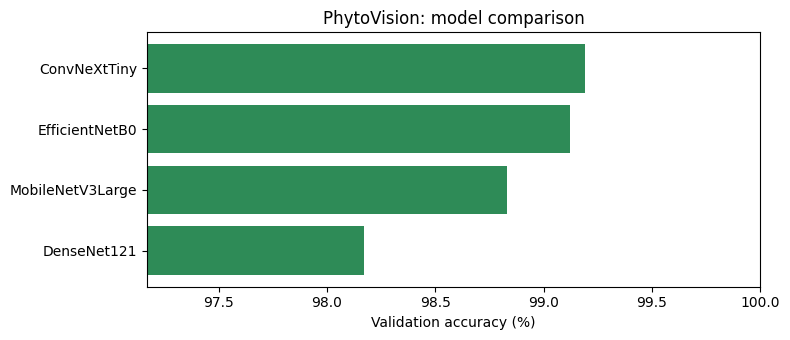

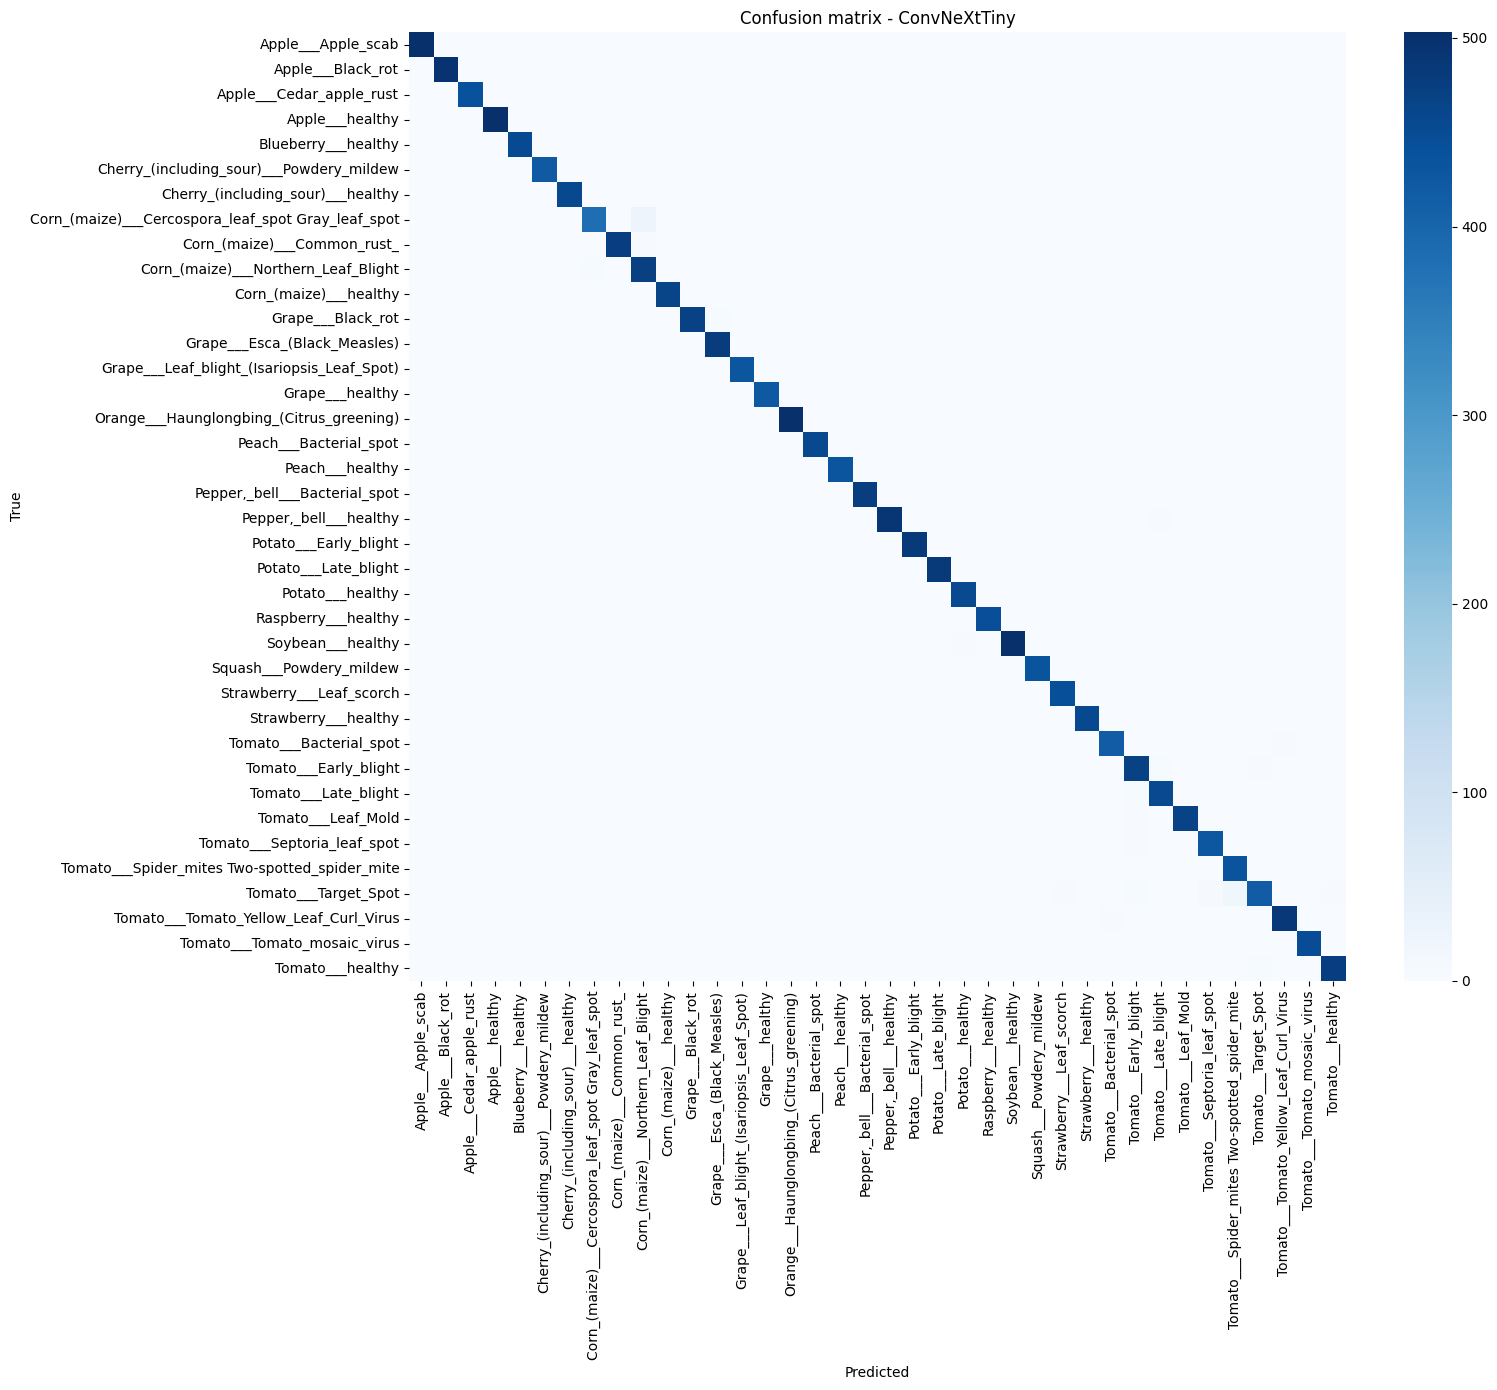

Best model: ConvNeXtTiny


In [6]:
# ===== CELL 5: leaderboard, chart, confusion matrix of the best model =====
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

df = (pd.read_csv(RESULTS_CSV).drop_duplicates('model', keep='last')
        .sort_values('val_acc', ascending=False).reset_index(drop=True))
df.index += 1
df.to_csv(f'{OUT_DIR}/leaderboard.csv')
display(df)

plt.figure(figsize=(8, 3.5))
plt.barh(df['model'][::-1], df['val_acc'][::-1] * 100, color='seagreen')
plt.xlim(max(0, df['val_acc'].min() * 100 - 1), 100)
plt.xlabel('Validation accuracy (%)'); plt.title('PhytoVision: model comparison')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/model_comparison.png', dpi=150); plt.show()

best = df.iloc[0]['model']
y_pred = np.load(f'{OUT_DIR}/{best}_ypred.npy')
pd.DataFrame(classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
             ).transpose().round(3).to_csv(f'{OUT_DIR}/{best}_classification_report.csv')
plt.figure(figsize=(16, 14))
sns.heatmap(confusion_matrix(y_true, y_pred), cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion matrix - {best}'); plt.xlabel('Predicted'); plt.ylabel('True')
plt.xticks(rotation=90); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/{best}_confusion_matrix.png', dpi=150); plt.show()
print('Best model:', best)

In [7]:
   import json; json.dump(class_names, open(f'{OUT_DIR}/class_names.json','w'))

In [8]:
import tensorflow as tf; print(tf.__version__)

2.21.0
